<a href="https://colab.research.google.com/github/dyuthidhara/demo/blob/main/Reproductible%20simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (100, 4)

First five observations:
   heart_rate_bpm  eda_simulated_units_per_hour  subjective_state_simulated  \
0       70.676101                      1.844252                   10.006095   
1       68.062935                      2.726194                   10.007082   
2       71.724127                      1.946441                   10.008227   
3       72.187449                      2.544692                   10.009559   
4       66.489469                      1.763146                   10.011106   

   task_time  
0          1  
1          2  
2          3  
3          4  
4          5  

Descriptive statistics:
       heart_rate_bpm  eda_simulated_units_per_hour  \
count          100.00                        100.00   
mean            74.98                          5.84   
std              3.24                          2.58   
min             66.49                          1.66   
25%             72.25                          3.57   
50%             75.12         

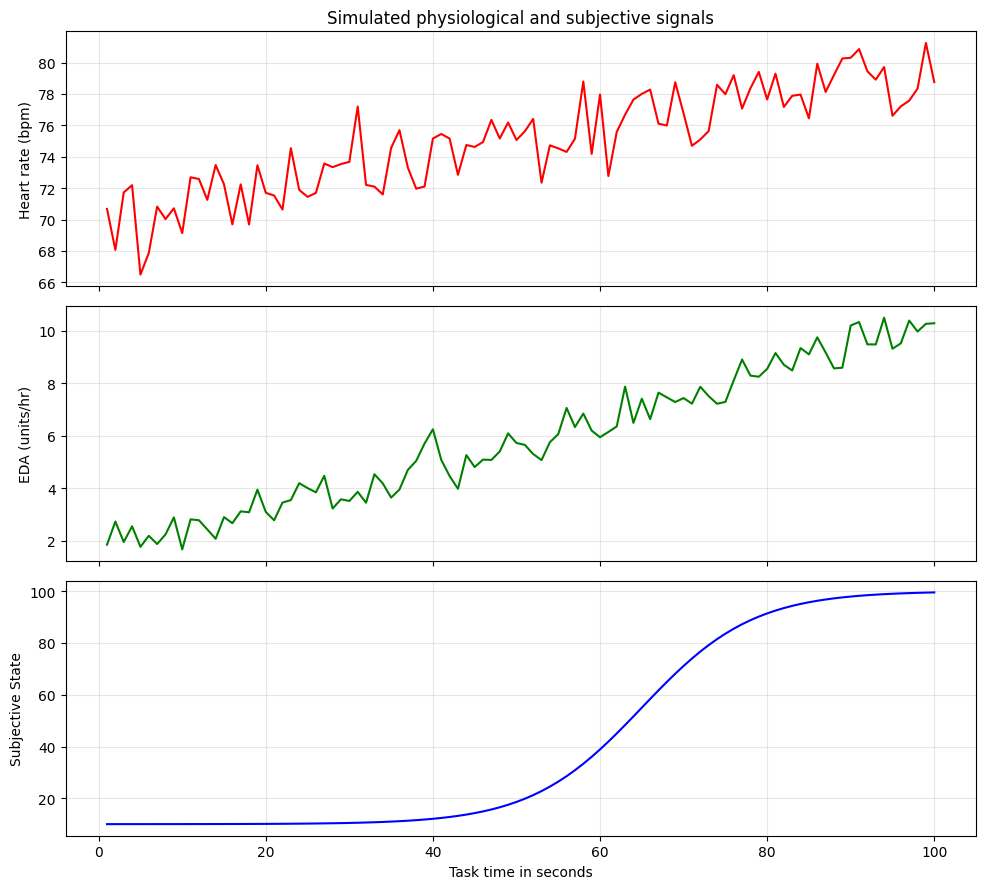


Saved data and figure in the outputs/ folder.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

n_points = 100
timeline = np.arange(1, n_points + 1)

heart_rate = 70 + (timeline ** 1.1) / 15 + rng.normal(0, 2, n_points)
eda = 2 + (timeline ** 1.2) / 30 + rng.normal(0, 0.5, n_points)
subjective_state = 10 + 90 / (1 + np.exp(-0.15 * (timeline - 65)))

df = pd.DataFrame({
    "heart_rate_bpm": heart_rate,
    "eda_simulated_units_per_hour": eda,
    "subjective_state_simulated": subjective_state,
    "task_time": timeline
})

print("Dataset shape:", df.shape)
print("\nFirst five observations:")
print(df.head())

print("\nDescriptive statistics:")
print(df.describe().round(2))

correlations = df[
    ["heart_rate_bpm", "eda_simulated_units_per_hour", "subjective_state_simulated"]
].corr(method="spearman")
print("\nSpearman correlation matrix:")
print(correlations.round(3))

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(df["task_time"], df["heart_rate_bpm"], color='r')
axes[0].set_ylabel("Heart rate (bpm)")
axes[0].set_title("Simulated physiological and subjective signals")
axes[0].grid(alpha=0.3)

axes[1].plot(df["task_time"], df["eda_simulated_units_per_hour"], color='g')
axes[1].set_ylabel("EDA (units/hr)")
axes[1].grid(alpha=0.3)

axes[2].plot(df["task_time"], df["subjective_state_simulated"], color='b')
axes[2].set_ylabel("Subjective State")
axes[2].set_xlabel("Task time in seconds")
axes[2].grid(alpha=0.3)

fig.tight_layout()
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

df.to_csv(output_dir / "simulated_data.csv", index=False)
fig.savefig(output_dir / "simulated_signals.png", dpi=200, bbox_inches="tight")
plt.show()

print("\nSaved data and figure in the outputs/ folder.")

INTERPRETATION
The simulated signals illustrate physiological measurements generated over a subjective task time. Using Spearman coefficient and descriptive task times, the generated data quantifies the associations between variables being interpretated cautiously. The variables show a time-dependent trend by construction and it does not show a common relationship between phyiological arousal and subjective experience. This graph represents a simulation and now real participant data